# Q7 - Train and save the churn model

Goal: a small model that predicts `still_active` from the player table only, so it is easy to use.

Choices:
- Random forest: the best in notebook 06, and no scaling needed.
- 12 features instead of 68: recency, volume and a few behaviour features that someone can read from a player profile. They score the same as all 68.
- The model gives the probability that the player is still active. Churn risk = 1 - that probability. A player is "at risk" when the churn risk is 0.5 or more.
- The final model is trained on all 840 players. The scores below come from cross-validation and a test set, not from the final model.
- The label is noisy (91 "active" players silent for 90+ days), so the score cannot be perfect.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))  # not needed after `pip install -e .`

from ubi_churn.config import DataCatalog, load_params

catalog = DataCatalog.from_config()  # conf/base/catalog.yml
params = load_params()  # conf/base/parameters.yml

import numpy as np
import pandas as pd
import polars as pl

from ubi_churn.utils import ml

CM: dict = params['churn_model']  # seed, split, threshold, random forest, feature_info
TARGET: str = params['target']
SEED: int = CM['seed']

# name -> (label, unit / meaning), in the order they appear in the app
FEATURE_INFO: dict[str, tuple[str, str]] = {k: tuple(v) for k, v in CM['feature_info'].items()}
FEATURES: list[str] = list(FEATURE_INFO)

df_players: pl.DataFrame = catalog.load('player_features')
X: pd.DataFrame = df_players.select(FEATURES).to_pandas()
y: np.ndarray = df_players[TARGET].to_numpy().astype(int)
print(X.shape, '| active share:', round(y.mean(), 3))
X.describe().T.round(2)

(840, 12) | active share: 0.419


,count,mean,std,min,25%,50%,75%,max
days_since_last_match,840.0,124.98,111.32,0.00,16.94,99.81,222.69,363.73
matches_last_30d,840.0,8.99,28.75,0.00,0.00,0.00,1.00,374.00
matches_last_90d,840.0,24.86,69.16,0.00,0.00,0.00,14.00,695.00
matches,840.0,113.97,214.27,1.00,5.00,27.50,111.25,1974.00
tenure_days,840.0,122.75,131.92,0.00,2.55,55.77,246.19,363.91
sessions_per_week,840.0,2.75,2.91,0.05,1.00,1.65,3.50,23.60
share_night,840.0,0.30,0.33,0.00,0.00,0.17,0.52,1.00
stay_after_loss,715.0,0.49,0.26,0.00,0.34,0.50,0.62,1.00
share_pvp_ranked,840.0,0.26,0.36,0.00,0.00,0.00,0.56,1.00
n_modes,840.0,1.91,0.86,1.00,1.00,2.00,3.00,3.00


## 1. Evaluate before saving

Cross-validation (5 folds, repeated 3 times) and a 20% test set, for a dummy baseline, one feature only, logistic regression and the random forest.

In [2]:
MODELS: dict = ml.make_candidate_models(FEATURES, params['model_selection']['single_feature'], SEED, CM['random_forest'])
df_eval: pd.DataFrame = ml.evaluate_candidates(MODELS, X, y, SEED, CM['test_size'], CM['cv_splits'], CM['cv_repeats'])
df_eval

,model,cv_roc_auc,cv_pr_auc,holdout_roc_auc,holdout_pr_auc
0,dummy (prior),0.500 +/- 0.000,0.420 +/- 0.002,0.500,0.417
1,1 feature (days_since_last_match),0.780 +/- 0.029,0.773 +/- 0.032,0.827,0.788
2,logistic regression,0.811 +/- 0.037,0.796 +/- 0.033,0.823,0.801
3,random forest,0.820 +/- 0.032,0.808 +/- 0.029,0.841,0.809


## 2. Decision threshold

How many churners we catch (recall) and how many alerts are right (precision) for different thresholds. Most players churn (58%), so a low threshold flags almost everyone. We keep 0.5. Lower = catch more churners, higher = fewer false alarms.

In [3]:
oof = ml.out_of_fold_proba(MODELS['random forest'][0], X, y, SEED)
risk, churned = 1 - oof, 1 - y
THRESHOLD: float = CM['threshold_churn_risk']
print(f'default churn-risk threshold: {THRESHOLD:.2f} (max-F1 threshold would be {ml.pick_threshold(churned, risk):.2f})')
ml.threshold_table(churned, risk, CM['threshold_grid'])

default churn-risk threshold: 0.50 (max-F1 threshold would be 0.32)


,threshold,players flagged,precision,recall
0,0.3,663,0.709,0.963
1,0.4,605,0.736,0.912
2,0.5,543,0.766,0.852
3,0.6,475,0.802,0.781
4,0.7,373,0.831,0.635
5,0.8,256,0.867,0.455


## 3. Train on all players and save

We save the model with its feature list, the median and range of each feature (used by the form in notebook 08), the threshold and the scores. Then we reload it and check the predictions are the same.

In [4]:
# same artifact as the pipeline node `train` (python -m ubi_churn.pipeline --nodes train)
model = ml.fit_final_model(X, y, SEED, CM['random_forest'])
artifact: dict = ml.build_model_artifact(
    model, X, y, FEATURE_INFO, THRESHOLD, df_eval.set_index('model').loc['random forest'].to_dict(), CM['note'],
)
model_path = catalog.save('churn_model', artifact)

reloaded = catalog.load('churn_model')
same = np.allclose(reloaded['model'].predict_proba(X)[:, 1], model.predict_proba(X)[:, 1])
print(f'saved {model_path} ({model_path.stat().st_size / 1e6:.1f} MB) | reload gives identical predictions: {same}')
print('threshold:', round(reloaded['threshold_churn_risk'], 2), '| metrics:', reloaded['metrics'])

saved C:\Users\vares\Documents\Ubi player\ubi_churn\data\06_models\churn_model.joblib (5.0 MB) | reload gives identical predictions: True
threshold: 0.5 | metrics: {'cv_roc_auc': '0.820 +/- 0.032', 'cv_pr_auc': '0.808 +/- 0.029', 'holdout_roc_auc': 0.841, 'holdout_pr_auc': 0.809}


## 4. SHAP: what pushes the prediction?

A dot on the right raises the churn risk, on the left lowers it. Red = high value of the feature. This is computed on the training players, so it shows how the model behaves, not how good it is.

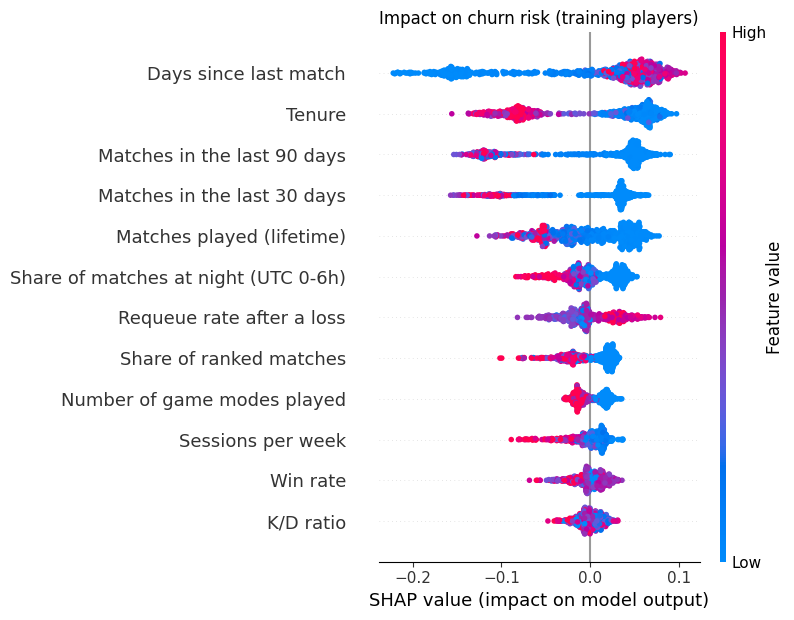

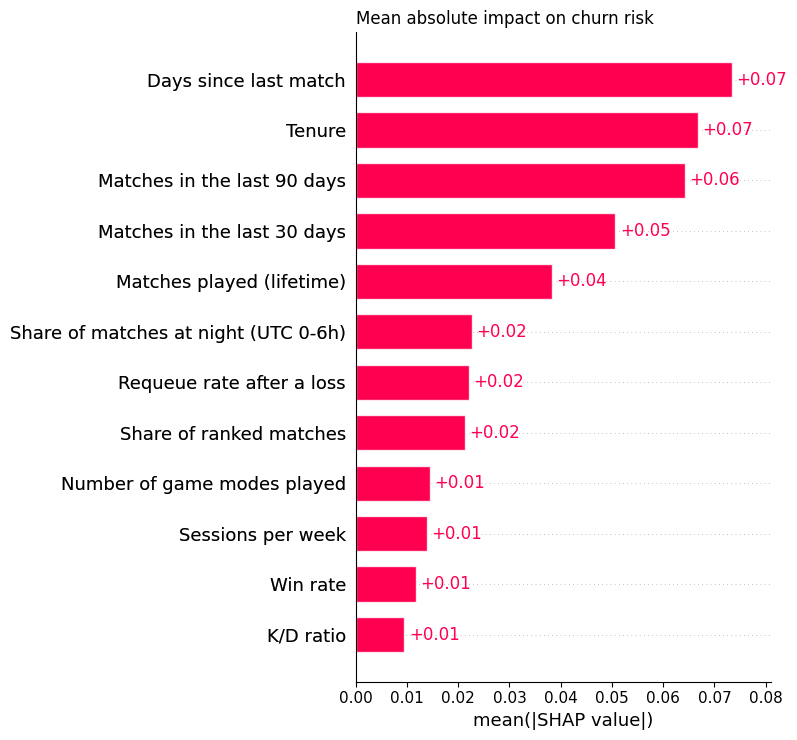

In [5]:
predictor = ml.ChurnPredictor(artifact)
ml.plot_shap_summary(predictor.explain(X), 'Impact on churn risk (training players)')